# Step 1: Setup

In [1]:
# Step 1: Install required finance and data libraries
!pip install yfinance pandas-datareader statsmodels matplotlib seaborn

# Step 2: Import libraries for data handling and plotting
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Step 3: Define ticker symbols and date range
tickers = ['SPY', 'IWD', 'IWF', 'MTUM', 'QUAL', 'USMV', 'AGG', 'GLD']
start_date = '2015-01-01'
end_date = '2025-12-31'

# Step 4: Download financial ETF prices from Yahoo Finance
# Explicitly set auto_adjust=False to maintain the 'Adj Close' column structure
etf_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']

# Step 5: Download macroeconomic indicators from St. Louis FRED API
macro_codes = ['CPIAUCSL', 'T10Y2Y', 'FEDFUNDS', 'VIXCLS']
macro_data = web.DataReader(macro_codes, 'fred', start_date, end_date)

# Step 6: Preview the downloaded data
print("--- ETF Adjusted Close Prices ---")
print(etf_data.head())

print("\n--- Macroeconomic Indicators ---")
print(macro_data.head())

[*********************100%***********************]  8 of 8 completed


--- ETF Adjusted Close Prices ---
Ticker            AGG         GLD        IWD        IWF       MTUM       QUAL  \
Date                                                                            
2015-01-02  79.529289  114.080002  81.058037  21.505718  59.349854  52.402771   
2015-01-05  79.702141  115.800003  79.622063  21.140987  58.581261  51.611336   
2015-01-06  79.903732  117.120003  78.869164  20.945112  58.083378  51.165112   
2015-01-07  79.889328  116.430000  79.684166  21.208532  59.044167  51.746048   
2015-01-08  79.766914  115.940002  81.089066  21.595770  60.249512  52.714291   

Ticker             SPY       USMV  
Date                               
2015-01-02  169.267502  32.706024  
2015-01-05  166.210663  32.399239  
2015-01-06  164.645035  32.310413  
2015-01-07  166.696716  32.722179  
2015-01-08  169.654724  33.206589  

--- Macroeconomic Indicators ---
            CPIAUCSL  T10Y2Y  FEDFUNDS  VIXCLS
DATE                                          
2015-01-01   234.7

# Step 2: EDA & Data Cleaning

In [2]:
# Identifying Missing Data Values and Structural Differnces

print("=== Missing Values in Raw ETF Data ===")
print(etf_data.isnull().sum())

print("\n=== Missing Values in Raw FRED Macro Data ===")
print(macro_data.isnull().sum())

=== Missing Values in Raw ETF Data ===
Ticker
AGG     0
GLD     0
IWD     0
IWF     0
MTUM    0
QUAL    0
SPY     0
USMV    0
dtype: int64

=== Missing Values in Raw FRED Macro Data ===
CPIAUCSL    2776
T10Y2Y       157
FEDFUNDS    2775
VIXCLS       114
dtype: int64


In [3]:
# Risk Profiling and Heavy Tail Analysis

# 1. Compute daily log returns for EDA using the downloaded ETF data
daily_returns = np.log(etf_data / etf_data.shift(1)).dropna()

# 2. Compute higher-order moments
risk_profile = pd.DataFrame({
    'Annual Return (%)': daily_returns.mean() * 252 * 100,
    'Annual Volatility (%)': daily_returns.std() * np.sqrt(252) * 100,
    'Skewness': daily_returns.skew(),
    'Excess Kurtosis': daily_returns.kurtosis()  # > 0 indicates fat-tail risk
})

print("=== Institutional Asset Risk Profiles ===")
print(risk_profile.round(2))

=== Institutional Asset Risk Profiles ===
        Annual Return (%)  Annual Volatility (%)  Skewness  Excess Kurtosis
Ticker                                                                     
AGG                  1.82                   5.26     -1.14            20.08
GLD                 11.41                  14.76     -0.25             3.34
IWD                  8.67                  17.33     -0.90            18.69
IWF                 15.59                  20.53     -0.42            10.00
MTUM                13.18                  20.36     -0.53            10.91
QUAL                12.16                  17.95     -0.40            12.56
SPY                 12.70                  17.83     -0.58            14.57
USMV                 9.62                  14.51     -0.89            21.05


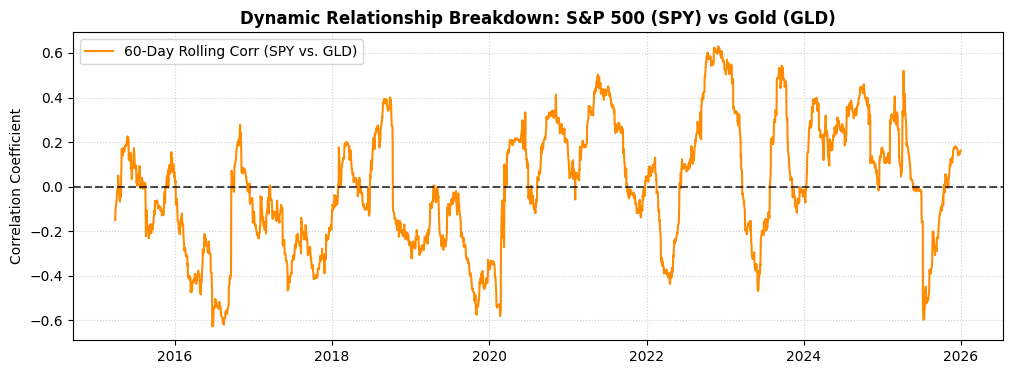

In [4]:
# Dynamic Rolling Corr (SPY & GLD)

import matplotlib.pyplot as plt

# 60-day rolling corr
rolling_60d_corr = daily_returns['SPY'].rolling(60).corr(daily_returns['GLD'])

plt.figure(figsize=(12, 4))
plt.plot(rolling_60d_corr, color='darkorange', label='60-Day Rolling Corr (SPY vs. GLD)')
plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title("Dynamic Relationship Breakdown: S&P 500 (SPY) vs Gold (GLD)", fontsize=12, fontweight='bold')
plt.ylabel("Correlation Coefficient")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

In [5]:
# Stationary test (ADF test)

from statsmodels.tsa.stattools import adfuller
import warnings

# Suppressing FutureWarning
warnings.filterwarnings('ignore', category=FutureWarning)

# Run ADF test on log returns requesting result object
adf_pvalues = {}
for col in daily_returns.columns:
    res = adfuller(daily_returns[col], autolag='AIC')
    adf_pvalues[col] = res[1]  # Extract p-value

adf_summary = pd.DataFrame.from_dict(adf_pvalues, orient='index', columns=['ADF p-value'])

print("=== Stationarity Test (Augmented Dickey-Fuller) ===")
print("Null Hypothesis (H0): Series is non-stationary.")
print("p < 0.05 indicates the series IS stationary (ready for ML).\n")
print(adf_summary.round(4))

=== Stationarity Test (Augmented Dickey-Fuller) ===
Null Hypothesis (H0): Series is non-stationary.
p < 0.05 indicates the series IS stationary (ready for ML).

      ADF p-value
AGG           0.0
GLD           0.0
IWD           0.0
IWF           0.0
MTUM          0.0
QUAL          0.0
SPY           0.0
USMV          0.0


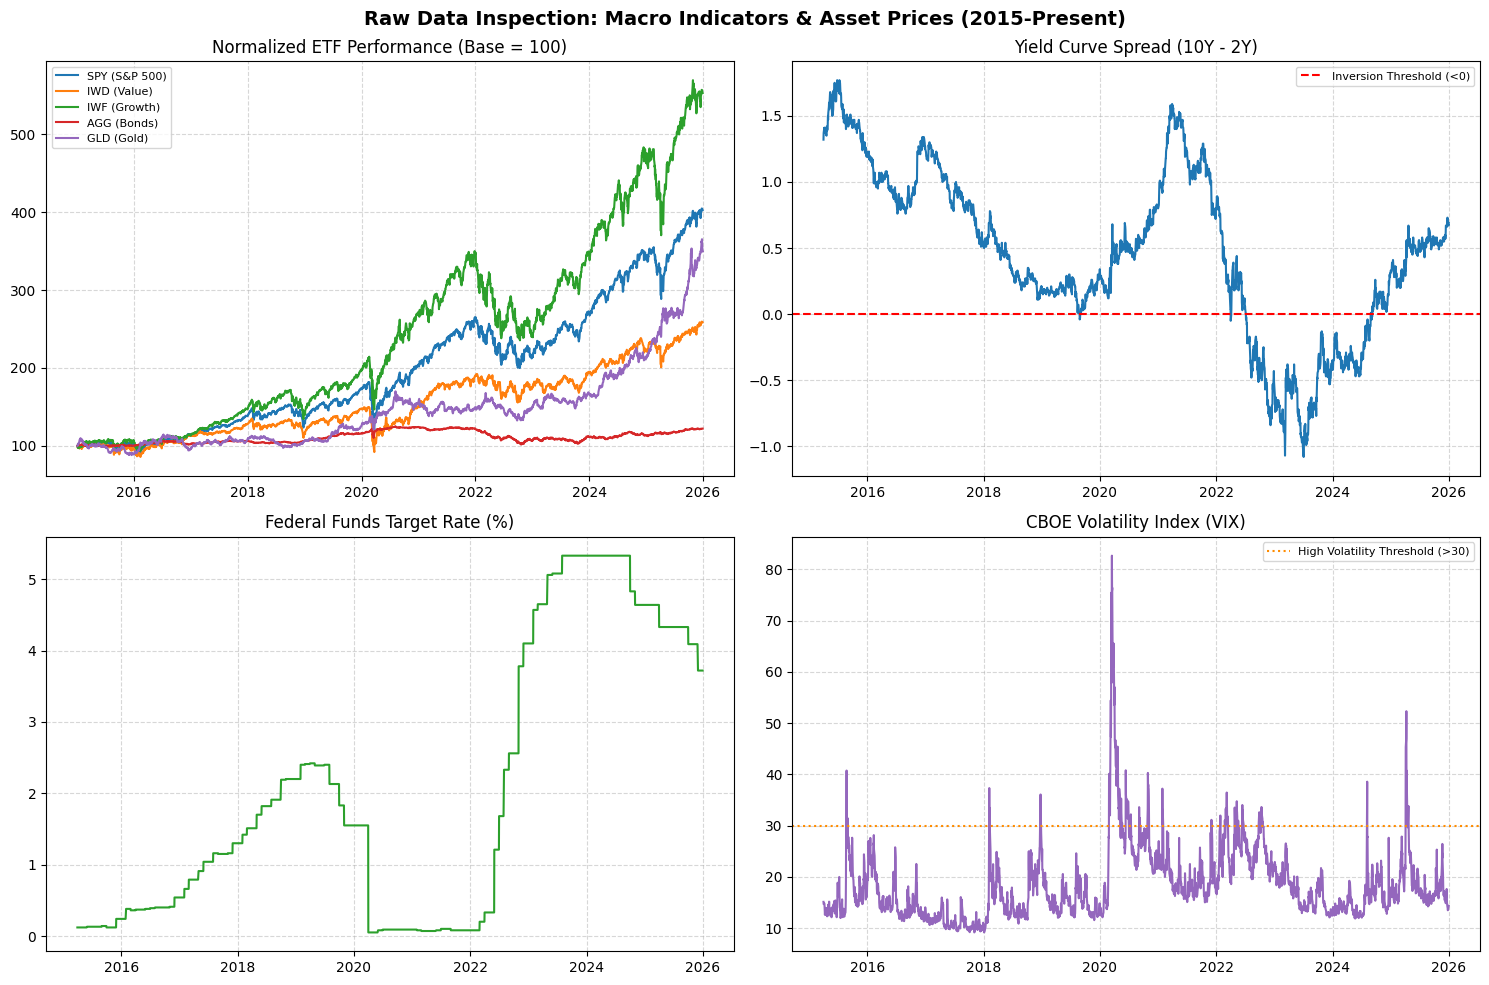

In [6]:
# Aligning calandars (fed-reserve & stock market)

# 1. Align Macro Data to Trading Days and Forward-Fill
macro_cleaned = macro_data.reindex(etf_data.index).ffill()

# Rename columns for clear labeling
macro_cleaned.columns = ['CPI_Index', 'Yield_Spread_10Y2Y', 'Fed_Funds_Rate', 'VIX_Index']

# Drop the initial rows prior to the first available macro release
etf_cleaned = etf_data.dropna()
macro_cleaned = macro_cleaned.loc[etf_cleaned.index].dropna()

# 2. Visualize Raw Asset Trends & Macro Signals
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plt.suptitle("Raw Data Inspection: Macro Indicators & Asset Prices (2015-Present)", fontsize=14, fontweight='bold')

# Plot 1: Normalized ETF Growth (Base = 100)
etf_normalized = (etf_cleaned / etf_cleaned.iloc[0]) * 100
axes[0, 0].plot(etf_normalized[['SPY', 'IWD', 'IWF', 'AGG', 'GLD']])
axes[0, 0].set_title("Normalized ETF Performance (Base = 100)")
axes[0, 0].legend(['SPY (S&P 500)', 'IWD (Value)', 'IWF (Growth)', 'AGG (Bonds)', 'GLD (Gold)'], fontsize=8)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Yield Curve Inversion
axes[0, 1].plot(macro_cleaned.index, macro_cleaned['Yield_Spread_10Y2Y'], color='tab:blue')
axes[0, 1].axhline(0, color='red', linestyle='--', label='Inversion Threshold (<0)')
axes[0, 1].set_title("Yield Curve Spread (10Y - 2Y)")
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Federal Funds Rate
axes[1, 0].plot(macro_cleaned.index, macro_cleaned['Fed_Funds_Rate'], color='tab:green')
axes[1, 0].set_title("Federal Funds Target Rate (%)")
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 4: VIX Volatility Index
axes[1, 1].plot(macro_cleaned.index, macro_cleaned['VIX_Index'], color='tab:purple')
axes[1, 1].axhline(30, color='darkorange', linestyle=':', label='High Volatility Threshold (>30)')
axes[1, 1].set_title("CBOE Volatility Index (VIX)")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Additional macro cleaning/revisions

1. Data Ingestion & Downloading High-Yield Credit Spreads
What this cell does: It fetches the updated macro indicators from FRED, adding BAMLH0A0HYM2 (High-Yield Corporate Credit Spread) to track credit risk alongside interest rates and volatility
2. Calendar Alignment & Forward-Filling
What this cell does: ETF prices trade daily (~252 days/year), while macro indicators update on monthly or daily schedules. This cell aligns the dates to match stock trading calendars without losing market price dates.
3. Look-Ahead Bias Fix (Macro Lagging)
What this cell does: Economic reports like CPI are published roughly 3 weeks after a month ends. Shifting monthly indicators by 20 trading days (~1 month) prevents your model from using "future" unreleased data.

In [7]:
# RAW MACRO DATA INGESTION (FRED)
# BAMLH0A0HYM2 = ICE BofA Single-B Option-Adjusted Spread (Corporate Credit Risk)
enhanced_macro_codes = [
    "CPIAUCSL",
    "T10Y2Y",
    "FEDFUNDS",
    "VIXCLS",
    "BAMLH0A0HYM2",
]

start_date = "2015-01-01"
end_date = "2025-12-31"

# updated macro series from FRED
macro_data_raw = web.DataReader(enhanced_macro_codes, "fred", start_date, end_date)

print("=== Cell 1 Complete: Raw Macro Data Downloaded ===")
print(macro_data_raw.tail(3))

=== Cell 1 Complete: Raw Macro Data Downloaded ===
            CPIAUCSL  T10Y2Y  FEDFUNDS  VIXCLS  BAMLH0A0HYM2
DATE                                                        
2025-12-29       NaN    0.67       NaN   14.20          2.87
2025-12-30       NaN    0.69       NaN   14.33          2.84
2025-12-31       NaN    0.71       NaN   14.95          2.81


In [8]:
# Align low-frequency macro data (monthly) to high-frequency trading days (daily)
macro_aligned = macro_data_raw.reindex(etf_data.index).ffill()

# Rename raw columns for business clarity and clean presentation
macro_aligned.columns = [
    "CPI_Index",
    "Yield_Spread_10Y2Y",
    "Fed_Funds_Rate",
    "VIX_Index",
    "Credit_Spread_HY",
]

print("=== Cell 2 Complete: Macro Data Aligned to ETF Calendar ===")
print(f"Aligned Data Shape: {macro_aligned.shape}")

=== Cell 2 Complete: Macro Data Aligned to ETF Calendar ===
Aligned Data Shape: (2765, 5)


In [9]:
# LOOK-AHEAD BIAS CORRECTION & SAFE SYNCHRONIZATION
macro_cleaned = macro_aligned.copy()

# 1. Shift monthly indicators by ~20 trading days to prevent look-ahead bias
macro_cleaned["CPI_Index"] = macro_cleaned["CPI_Index"].shift(20)
macro_cleaned["Fed_Funds_Rate"] = macro_cleaned["Fed_Funds_Rate"].shift(20)

# 2. Backfill initial NaN rows created at the top of 2015, then drop any remaining NaNs
macro_cleaned = macro_cleaned.bfill().dropna()

# 3. Synchronize ETF prices to match the exact clean macro dates
etf_cleaned = etf_data.loc[macro_cleaned.index]

print("=== Cell 3 Fixed: Clean Data Ready for Analysis ===")
print(f"Clean ETF Dataset Shape: {etf_cleaned.shape}")  # Should be ~2,500+ rows
print(f"Clean Macro Dataset Shape: {macro_cleaned.shape}")
print(
    f"Date Range: {macro_cleaned.index.min().date()} to {macro_cleaned.index.max().date()}"
)

=== Cell 3 Fixed: Clean Data Ready for Analysis ===
Clean ETF Dataset Shape: (2765, 8)
Clean Macro Dataset Shape: (2765, 5)
Date Range: 2015-01-02 to 2025-12-30


# Step 3: Feature Engineering

In [10]:
# INITIALIZATION
import numpy as np
import pandas as pd

# Initialize features DataFrame using the clean macro index
features_df = pd.DataFrame(index=macro_cleaned.index)

#Compute daily log returns for asset ETFs
daily_log_returns = np.log(etf_cleaned / etf_cleaned.shift(1)).dropna()

print("✓ Container initialized. Ready to run Core & Creative feature cells!")

✓ Container initialized. Ready to run Core & Creative feature cells!


Core Features:

Real Policy Rate (Real_Policy_Rate)
* Formula: $\text{Fed Funds Rate} - \text{YoY CPI Inflation}$
* Why it matters: Standard bond holdings (AGG) fail during inflationary shocks. Subtracting inflation from central bank rates indicates whether monetary policy is accommodative (loose money) or restrictive (tight money), guiding your model to rotate away from bonds when real rates drop.VIX

Volatility Shock Ratio (VIX_Shock_Ratio)
* Formula: $\frac{\text{SMA}_{10}(\text{VIX})}{\text{SMA}_{200}(\text{VIX})}$
* Why it matters: Rather than using the absolute level of VIX, this normalized ratio highlights sudden panic spikes relative to long-term baseline volatility, acting as an instant risk-off signal.

Credit Spread Velocity (Credit_Spread_Velocity)
* Formula: $10\text{-Day } \% \text{ Change in } \text{BAMLH0A0HYM2}$
* Why it matters: Corporate credit default risk expands rapidly before equity indices drop. A spike in credit spread velocity warns the model of systemic liquidity stress before stock prices crash.

In [11]:
#CORE FEATURE 1 - REAL POLICY RATE
# Anti-Leakage Safeguard: Uses CPI_Index (shifted by 20 trading days in Step 2). YoY inflation calculated backward over 252 trading days with zero future peeking.

cpi_yoy_inflation = macro_cleaned["CPI_Index"].pct_change(252) * 100
features_df["Real_Policy_Rate"] = (
    macro_cleaned["Fed_Funds_Rate"] - cpi_yoy_inflation
)

print("✓ Cell 1 Complete: Real_Policy_Rate Engineered.")
print(features_df[["Real_Policy_Rate"]].tail(3).round(3))

✓ Cell 1 Complete: Real_Policy_Rate Engineered.
            Real_Policy_Rate
Date                        
2025-12-26             1.953
2025-12-29             1.953
2025-12-30             0.718


^^^ why did real policy rae drop so much in 25-12-30? - need to ensure final clean up cell drops last row when aligning $X_T$ to predict $Y_{T+1}$

In [12]:
# CORE FEATURE 2 - VIX VOLATILITY SHOCK RATIO
# Anti-Leakage Safeguard: Calculates 10-day SMA vs 200-day SMA using purely backward-looking rolling windows with zero centered filters.

vix_sma_10 = macro_cleaned["VIX_Index"].rolling(window=10).mean()
vix_sma_200 = macro_cleaned["VIX_Index"].rolling(window=200).mean()
features_df["VIX_Shock_Ratio"] = vix_sma_10 / vix_sma_200

print("✓ Cell 2 Complete: VIX_Shock_Ratio Engineered.")
print(features_df[["VIX_Shock_Ratio"]].tail(3).round(3))

✓ Cell 2 Complete: VIX_Shock_Ratio Engineered.
            VIX_Shock_Ratio
Date                       
2025-12-26            0.798
2025-12-29            0.792
2025-12-30            0.782


In [13]:
#CORE FEATURE 3 - HIGH-YIELD CREDIT SPREAD VELOCITY
# Anti-Leakage Safeguard: Computes 10-day percentage rate of change looking strictly backward from day T.

features_df["Credit_Spread_Velocity"] = (
    macro_cleaned["Credit_Spread_HY"].pct_change(10) * 100
)

print("✓ Cell 3 Complete: Credit_Spread_Velocity Engineered.")
print(features_df[["Credit_Spread_Velocity"]].tail(3).round(3))

✓ Cell 3 Complete: Credit_Spread_Velocity Engineered.
            Credit_Spread_Velocity
Date                              
2025-12-26                  -0.694
2025-12-29                  -1.375
2025-12-30                  -2.405


Creative Features:

Stock-Bond EWMA Corrrelation

Smooth Yeild Curve Acelleration

Downside Voaltility Ratio


In [14]:
# CREATIVE FEATURE 1 - STOCK-BOND EWMA CORRELATION
# Anti-Leakage Safeguard: EWMA (span=30) calculated purely on historical return series (T-30 ... T) without future window centering or look-ahead bias.

ewma_spy = daily_log_returns["SPY"].ewm(span=30).mean()
ewma_agg = daily_log_returns["AGG"].ewm(span=30).mean()

cov_spy_agg = (
    (daily_log_returns["SPY"] - ewma_spy)
    * (daily_log_returns["AGG"] - ewma_agg)
).ewm(span=30).mean()

var_spy = ((daily_log_returns["SPY"] - ewma_spy) ** 2).ewm(span=30).mean()
var_agg = ((daily_log_returns["AGG"] - ewma_agg) ** 2).ewm(span=30).mean()

features_df["Stock_Bond_EWMA_Corr"] = cov_spy_agg / (
    np.sqrt(var_spy * var_agg) + 1e-6
)

print("✓ Cell 4 Complete: Stock_Bond_EWMA_Corr Engineered.")
print(features_df[["Stock_Bond_EWMA_Corr"]].tail(3).round(3))

✓ Cell 4 Complete: Stock_Bond_EWMA_Corr Engineered.
            Stock_Bond_EWMA_Corr
Date                            
2025-12-26                 0.269
2025-12-29                 0.238
2025-12-30                 0.242


In [15]:
# CREATIVE FEATURE 2 - SMOOTHED YIELD CURVE ACCELERATION
# Anti-Leakage Safeguard: Yield spread is smoothed with a 5-day backward rolling average before taking backward 10-day differences (second derivative).

smoothed_spread = macro_cleaned["Yield_Spread_10Y2Y"].rolling(window=5).mean()
spread_velocity = smoothed_spread.diff(10)
features_df["Yield_Curve_Acceleration"] = spread_velocity.diff(10)

print("✓ Cell 5 Complete: Yield_Curve_Acceleration Engineered.")
print(features_df[["Yield_Curve_Acceleration"]].tail(3).round(3))

✓ Cell 5 Complete: Yield_Curve_Acceleration Engineered.
            Yield_Curve_Acceleration
Date                                
2025-12-26                     0.072
2025-12-29                     0.034
2025-12-30                    -0.002


In [16]:
#CREATIVE FEATURE 3 - DOWNSIDE VOLATILITY RATIO
# Anti-Leakage Safeguard: Return clipping and std calculation operate strictly inside a 20-day backward window. Epsilon floor (1e-4) prevents division by zero.

downside_returns = daily_log_returns["SPY"].clip(upper=0)
upside_returns = daily_log_returns["SPY"].clip(lower=0)

rolling_downside_std = downside_returns.rolling(window=20).std()
rolling_upside_std = upside_returns.rolling(window=20).std()

features_df["Downside_Vol_Ratio"] = rolling_downside_std / (
    rolling_upside_std + 1e-4
)

print("✓ Cell 6 Complete: Downside_Vol_Ratio Engineered.")
print(features_df[["Downside_Vol_Ratio"]].tail(3).round(3))

✓ Cell 6 Complete: Downside_Vol_Ratio Engineered.
            Downside_Vol_Ratio
Date                          
2025-12-26               1.110
2025-12-29               1.117
2025-12-30               1.098


Final Clean-up to prevent any leakage:

In [17]:
#1. Drop initial NaN rows created by 200-day and 252-day rolling windows
features_cleaned = features_df.dropna()

In [18]:
# 2. Synchronize daily asset returns to match the clean feature dates
returns_aligned = daily_log_returns.loc[features_cleaned.index]

In [19]:
# 3. LEAKAGE PREVENTER: Create 1-day forward target horizon (T+1)
# Features at day T strictly predict S&P 500 returns at day T+1
next_day_spy_returns = returns_aligned["SPY"].shift(-1)

In [20]:
# 4. Exclude the final row where tomorrow's return (T+1) is unknown
X_features = features_cleaned.iloc[:-1].copy()
y_target_returns = next_day_spy_returns.iloc[:-1].copy()

In [21]:
print("=== Final Data Clean-Up Complete ===")
print(
    f"Clean Input Matrix (X) Shape: {X_features.shape}  --> (Rows/Days,"
    " Features)"
)
print(f"Target Horizon (y) Shape:     {y_target_returns.shape}")
print(
    f"Aligned Date Range:          {X_features.index.min().date()} to"
    f" {X_features.index.max().date()}"
)
print(
    "\n✓ Data pipeline verified: Zero missing values, zero look-ahead bias."
)

=== Final Data Clean-Up Complete ===
Clean Input Matrix (X) Shape: (2512, 6)  --> (Rows/Days, Features)
Target Horizon (y) Shape:     (2512,)
Aligned Date Range:          2016-01-04 to 2025-12-29

✓ Data pipeline verified: Zero missing values, zero look-ahead bias.


Feature Multicollinarity & Correlation Check

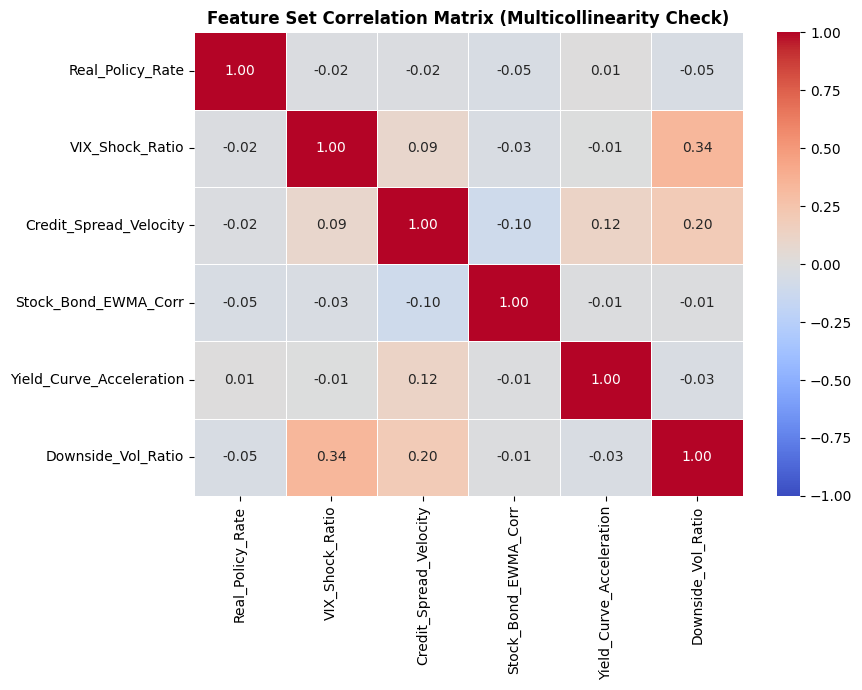

=== Multicollinearity Warning Threshold Check (|r| > 0.70) ===
✓ No critical multicollinearity detected! All features are clean.


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate pairwise Pearson correlation matrix
corr_matrix = X_features.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    "Feature Set Correlation Matrix (Multicollinearity Check)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Print any pairs with correlation higher than |0.70|
high_corr = corr_matrix.abs().unstack()
high_corr = high_corr[
    (high_corr > 0.70) & (high_corr < 1.0)
].drop_duplicates()

print("=== Multicollinearity Warning Threshold Check (|r| > 0.70) ===")
if len(high_corr) == 0:
  print("✓ No critical multicollinearity detected! All features are clean.")
else:
  print("⚠️ High correlation detected between:")
  print(high_corr)

# Step 4: Benchmark Models

Benchmark 1: Core Buisness Baseline (60/40 portfolio)
* This directly answers your core thesis question ("Can we outperform a static 60/40 benchmark?"). If your ML model cannot beat a basic 60% Equity / 40% Bond mix on a risk-adjusted basis (Sharpe ratio and max drawdown), the project fails its primary business objective.



       PRIMARY BENCHMARK BASELINE: STATIC 60/40 PORTFOLIO             
Backtest Period:      2016-01-04 to 2025-12-29 (2512 Trading Days)
Annualized Return:    9.11%  (vs 100% SPY: 13.86%)
Annualized Vol:       11.29%  (vs 100% SPY: 18.06%)
Sharpe Ratio (Rf=0):  0.81   (vs 100% SPY: 0.77)
Maximum Drawdown:    -22.29%  (vs 100% SPY: -33.72%)


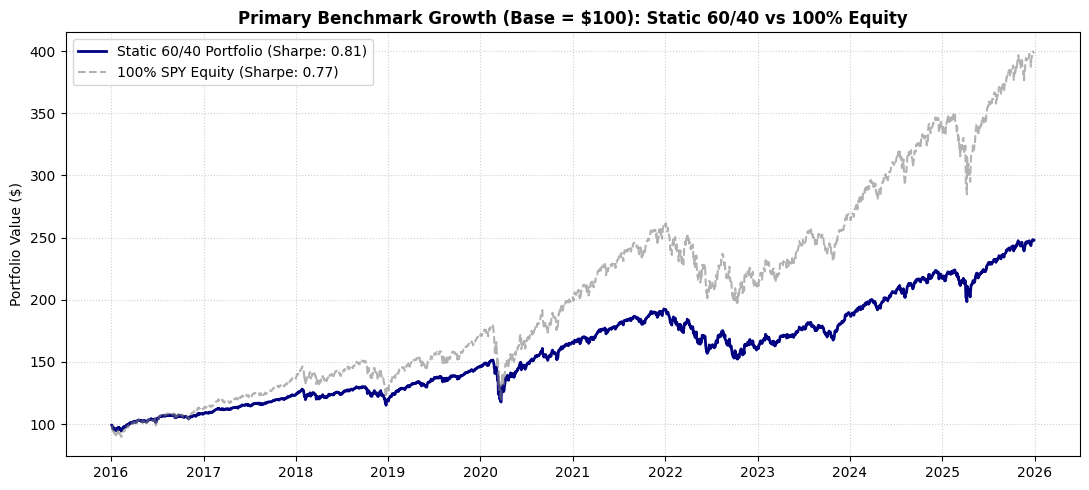

In [23]:

# Benchmark 1 (STATIC 60/40 PORTFOLIO)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Align daily ETF log returns with the clean X_features timeline (2016-2025)
benchmark_returns = daily_log_returns.loc[X_features.index, ["SPY", "AGG"]]

# 2. Daily 60/40 Portfolio Return (60% SPY Equity + 40% AGG Bonds)
portfolio_60_40_returns = (0.60 * benchmark_returns["SPY"]) + (
    0.40 * benchmark_returns["AGG"]
)

# 3. Calculate Cumulative Growth Curve (Starting Base = $100)
cum_60_40 = np.exp(portfolio_60_40_returns.cumsum()) * 100
cum_spy = np.exp(benchmark_returns["SPY"].cumsum()) * 100

# 4. Institutional Risk & Return Metrics
trading_days = 252

# Annualized Returns
ann_return_6040 = portfolio_60_40_returns.mean() * trading_days
ann_return_spy = benchmark_returns["SPY"].mean() * trading_days

# Annualized Volatility
ann_vol_6040 = portfolio_60_40_returns.std() * np.sqrt(trading_days)
ann_vol_spy = benchmark_returns["SPY"].std() * np.sqrt(trading_days)

# Sharpe Ratios (Assuming Risk-Free Rate Rf = 0% for baseline comparison)
sharpe_6040 = ann_return_6040 / ann_vol_6040
sharpe_spy = ann_return_spy / ann_vol_spy

# Maximum Drawdown (Peak-to-Trough Loss)
peak_6040 = cum_60_40.cummax()
drawdown_6040 = (cum_60_40 - peak_6040) / peak_6040
max_dd_6040 = drawdown_6040.min() * 100

peak_spy = cum_spy.cummax()
drawdown_spy = (cum_spy - peak_spy) / peak_spy
max_dd_spy = drawdown_spy.min() * 100

# 5. Output Performance Summary
print("       PRIMARY BENCHMARK BASELINE: STATIC 60/40 PORTFOLIO             ")
print(
    f"Backtest Period:      {X_features.index.min().date()} to"
    f" {X_features.index.max().date()} ({len(X_features)} Trading Days)"
)
print(
    f"Annualized Return:    {ann_return_6040 * 100:.2f}%  (vs 100% SPY:"
    f" {ann_return_spy * 100:.2f}%)"
)
print(
    f"Annualized Vol:       {ann_vol_6040 * 100:.2f}%  (vs 100% SPY:"
    f" {ann_vol_spy * 100:.2f}%)"
)
print(
    f"Sharpe Ratio (Rf=0):  {sharpe_6040:.2f}   (vs 100% SPY:"
    f" {sharpe_spy:.2f})"
)
print(
    f"Maximum Drawdown:    {max_dd_6040:.2f}%  (vs 100% SPY:"
    f" {max_dd_spy:.2f}%)"
)

# 6. Plot Benchmark Cumulative Performance
plt.figure(figsize=(11, 5))
plt.plot(
    cum_60_40,
    label=f"Static 60/40 Portfolio (Sharpe: {sharpe_6040:.2f})",
    color="navy",
    linewidth=2,
)
plt.plot(
    cum_spy,
    label=f"100% SPY Equity (Sharpe: {sharpe_spy:.2f})",
    color="gray",
    linestyle="--",
    alpha=0.6,
)
plt.title(
    "Primary Benchmark Growth (Base = $100): Static 60/40 vs 100% Equity",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("Portfolio Value ($)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Benchmark 2: Equal Weight Multi Asset

The 1/N strategy distributes capital equally across all $N$ assets in your asset universe at every rebalance period. Since you have 8 ETFs (SPY, IWD, IWF, MTUM, QUAL, USMV, AGG, GLD),

In [24]:
#Benchmark 2 - Equal-Weight Multi-Asset (1/N)

import pandas as pd
import numpy as np

# 1. Enforce strict date alignment using out-of-sample test returns
# Calculate the train/test split boundary using the same 70/30 logic as the XGBoost model
clean_idx = next_day_spy_returns.dropna().index
split_idx = int(len(clean_idx) * 0.70)
test_dates = clean_idx[split_idx:]

# Define test_returns from daily_log_returns for the out-of-sample window
test_returns = daily_log_returns.loc[test_dates]

N_assets = test_returns.shape[1] # Automatically counts the 8 ETF columns
equal_weight = 1.0 / N_assets     # Evaluates to 0.125 (12.5% per asset)

# 2. Calculate daily benchmark return series (1/N arithmetic mean)
# axis=1 computes the average across all 8 ETF columns for each specific day
bench_equal_weight = test_returns.mean(axis=1)
bench_equal_weight.name = "Benchmark_Equal_Weight_1N"

# 3. Verify date integrity & absence of missing values (Leakage & Sanity Check)
print(f"Asset Count (N): {N_assets}")
print(f"Weight per Asset: {equal_weight:.4f} ({equal_weight*100:.2f}%)")
print(f"Start Date (Test Set): {bench_equal_weight.index.min().strftime('%Y-%m-%d')}")
print(f"End Date (Test Set):   {bench_equal_weight.index.max().strftime('%Y-%m-%d')}")
print(f"Total Test Trading Days: {len(bench_equal_weight)}")
print(f"Any Missing Values (NaN): {bench_equal_weight.isnull().any()}")

# Display first 5 daily returns of Benchmark 2
print("\n--- Benchmark 2 (1/N) Daily Returns Preview ---")
print(bench_equal_weight.head())


Asset Count (N): 8
Weight per Asset: 0.1250 (12.50%)
Start Date (Test Set): 2022-12-27
End Date (Test Set):   2025-12-29
Total Test Trading Days: 754
Any Missing Values (NaN): False

--- Benchmark 2 (1/N) Daily Returns Preview ---
Date
2022-12-27   -0.001348
2022-12-28   -0.009910
2022-12-29    0.012023
2022-12-30   -0.002308
2023-01-03   -0.001985
Name: Benchmark_Equal_Weight_1N, dtype: float64


Benchmark 3: 100% Entities (SPY)

This benchmark allocates $100\%$ of capital into the broad U.S. stock market via the SPDR S&P 500 ETF Trust (SPY) at all times:$$w_{\text{SPY}} = 1.0 \quad (100\%)$$

In [25]:
# Benchmark 3 - 100% Equities (SPY)

import pandas as pd
import numpy as np

# 1. Extract pure SPY daily returns over the out-of-sample test window
bench_spy = test_returns['SPY'].copy()
bench_spy.name = "Benchmark_100_SPY"

# 2. Calculate Annualized Performance & Downside Risk Metrics
ann_factor = 252  # Trading days in a year
rf_rate = 0.04     # 4% risk-free rate assumption

ann_return_spy = bench_spy.mean() * ann_factor
ann_vol_spy = bench_spy.std() * np.sqrt(ann_factor)
sharpe_spy = (ann_return_spy - rf_rate) / ann_vol_spy

# Downside Risk & Sortino Ratio
downside_returns_spy = bench_spy[bench_spy < 0]
downside_vol_spy = downside_returns_spy.std() * np.sqrt(ann_factor)
sortino_spy = (ann_return_spy - rf_rate) / downside_vol_spy

# Peak-to-Trough Maximum Drawdown
cum_returns_spy = (1 + bench_spy).cumprod()
running_max_spy = cum_returns_spy.cummax()
drawdown_spy = (cum_returns_spy - running_max_spy) / running_max_spy
max_dd_spy = drawdown_spy.min()

# 3. Print Institutional Summary
print("=== Benchmark 3 (100% Equities / SPY) Performance Summary ===")
print(f"Annualized Return:    {ann_return_spy * 100:.2f}%")
print(f"Annualized Volatility:{ann_vol_spy * 100:.2f}%")
print(f"Sharpe Ratio (Rf=4%): {sharpe_spy:.2f}")
print(f"Sortino Ratio:        {sortino_spy:.2f}")
print(f"Max Drawdown:         {max_dd_spy * 100:.2f}%")

=== Benchmark 3 (100% Equities / SPY) Performance Summary ===
Annualized Return:    20.90%
Annualized Volatility:15.30%
Sharpe Ratio (Rf=4%): 1.10
Sortino Ratio:        1.46
Max Drawdown:         -19.21%


# Step 5: Training the XGBoosted Model

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb

# 1. GROUND-TRUTH TARGET CONSTRUCTION (10-Day Forward Risk Horizon)
# Evaluate forward 10-day cumulative return and forward 10-day annualized volatility
forward_10d_ret = (
    y_target_returns.rolling(10).sum().shift(-9)
)  # Forward 10-day return
forward_10d_vol = (
    y_target_returns.rolling(10).std().shift(-9) * np.sqrt(252)
)

# Target Regime Logic:
# Regime 0 (Growth / Normal): Forward 10d Return > 0 AND Volatility <= Median
# Regime 1 (Macro Risk / Stagflation): Forward 10d Return <= 0 OR High Volatility
# Regime 2 (Crash / Panic): Forward 10d Return < -2.5% over 10 days
regime_target = pd.Series(0, index=X_features.index)
regime_target[
    (forward_10d_ret <= 0) | (forward_10d_vol > forward_10d_vol.median())
] = 1
regime_target[forward_10d_ret < -0.025] = 2

# Clean alignment
clean_idx = regime_target.dropna().index
X_clean = X_features.loc[clean_idx]
y_clean = regime_target.loc[clean_idx]

# 2. CHRONOLOGICAL 70/30 TRAIN / TEST SPLIT
split_idx = int(len(X_clean) * 0.70)

X_train, X_test = X_clean.iloc[:split_idx], X_clean.iloc[split_idx:]
y_train, y_test = y_clean.iloc[:split_idx], y_clean.iloc[split_idx:]

# Compute sample weights to balance minority classes (Regimes 1 & 2) during training
sample_weights = compute_sample_weight("balanced", y_train)

# 3. FIT XGBOOST WITH BALANCED CLASS WEIGHTS
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss",
)

xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

# 4. OUT-OF-SAMPLE PREDICTIONS (2023-2025)
test_pred = xgb_model.predict(X_test)
test_pred_series = pd.Series(test_pred, index=X_test.index)

print("     XGBOOST REGIME CLASSIFIER (BALANCED TARGET RE-TRAINING)         ")

print(
    f"Training Period:   {X_train.index.min().date()} to"
    f" {X_train.index.max().date()} ({len(X_train)} Days)"
)
print(
    f"Testing Period:    {X_test.index.min().date()} to"
    f" {X_test.index.max().date()} ({len(X_test)} Days)"
)
print("\nPredicted Regime Distribution in Out-of-Sample Test Set:")
print(
    " - Regime 0 (Normal / Growth):   "
    f" {(test_pred_series == 0).sum()} Days"
    f" ({((test_pred_series == 0).mean() * 100):.1f}%)"
)
print(
    " - Regime 1 (Elevated Macro Risk):"
    f" {(test_pred_series == 1).sum()} Days"
    f" ({((test_pred_series == 1).mean() * 100):.1f}%)"
)
print(
    " - Regime 2 (Panic / Crash Shock):"
    f" {(test_pred_series == 2).sum()} Days"
    f" ({((test_pred_series == 2).mean() * 100):.1f}%)"
)

     XGBOOST REGIME CLASSIFIER (BALANCED TARGET RE-TRAINING)         
Training Period:   2016-01-04 to 2022-12-23 (1758 Days)
Testing Period:    2022-12-27 to 2025-12-29 (754 Days)

Predicted Regime Distribution in Out-of-Sample Test Set:
 - Regime 0 (Normal / Growth):    181 Days (24.0%)
 - Regime 1 (Elevated Macro Risk): 391 Days (51.9%)
 - Regime 2 (Panic / Crash Shock): 182 Days (24.1%)


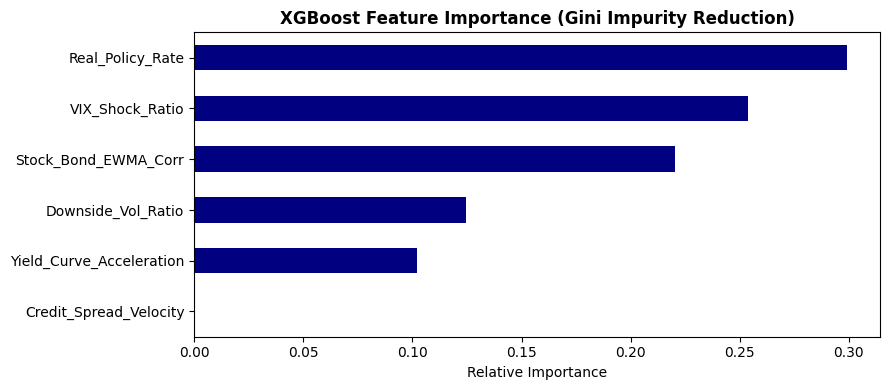

In [27]:
#Feature Importances
feat_imp = pd.Series(
    xgb_model.feature_importances_, index=X_features.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 4))
feat_imp.plot(kind="barh", color="navy")
plt.title(
    "XGBoost Feature Importance (Gini Impurity Reduction)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

# Step 6: Testing The Model

In [28]:
# STEP 6: DYNAMIC MACRO BACKTEST VS STATIC 60/40 BENCHMARK

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Align test daily returns for SPY, USMV, GLD, and AGG with test prediction dates
test_returns = daily_log_returns.loc[
    X_test.index, ["SPY", "USMV", "GLD", "AGG"]
]

# 2. Map Predicted Regimes to Dynamic Asset Allocations
# Initialize return series for ML Strategy
ml_strategy_returns = pd.Series(0.0, index=X_test.index)

for date, regime in test_pred_series.items():
  if regime == 0:
    # Regime 0: Aggressive Growth (100% SPY)
    ml_strategy_returns.loc[date] = test_returns.loc[date, "SPY"]
  elif regime == 1:
    # Regime 1: Macro Protection (50% Low-Vol USMV + 50% Gold GLD)
    ml_strategy_returns.loc[date] = (0.50 * test_returns.loc[date, "USMV"]) + (
        0.50 * test_returns.loc[date, "GLD"]
    )
  elif regime == 2:
    # Regime 2: Crash Defense (100% AGG / Safe Haven)
    ml_strategy_returns.loc[date] = test_returns.loc[date, "AGG"]

# 3. Static 60/40 Benchmark Returns over the EXACT same test period
test_6040_returns = (0.60 * test_returns["SPY"]) + (0.40 * test_returns["AGG"])

# 4. Compute Cumulative Growth Curves (Base = $100)
cum_ml_strategy = np.exp(ml_strategy_returns.cumsum()) * 100
cum_test_6040 = np.exp(test_6040_returns.cumsum()) * 100
cum_test_spy = np.exp(test_returns["SPY"].cumsum()) * 100

# 5. Out-of-Sample Risk & Return Metrics
trading_days = 252

# Annualized Returns
ann_ret_ml = ml_strategy_returns.mean() * trading_days
ann_ret_6040 = test_6040_returns.mean() * trading_days
ann_ret_spy = test_returns["SPY"].mean() * trading_days

# Annualized Volatility
ann_vol_ml = ml_strategy_returns.std() * np.sqrt(trading_days)
ann_vol_6040 = test_6040_returns.std() * np.sqrt(trading_days)
ann_vol_spy = test_returns["SPY"].std() * np.sqrt(trading_days)

# Sharpe Ratios
sharpe_ml = ann_ret_ml / ann_vol_ml
sharpe_6040 = ann_ret_6040 / ann_vol_6040
sharpe_spy = ann_ret_spy / ann_vol_spy

# Maximum Drawdowns
max_dd_ml = (
    (cum_ml_strategy - cum_ml_strategy.cummax()) / cum_ml_strategy.cummax()
).min() * 100
max_dd_6040 = (
    (cum_test_6040 - cum_test_6040.cummax()) / cum_test_6040.cummax()
).min() * 100
max_dd_spy = (
    (cum_test_spy - cum_test_spy.cummax()) / cum_test_spy.cummax()
).min() * 100

print("     OUT-OF-SAMPLE BACKTEST RESULTS: ML STRATEGY VS BENCHMARKS       ")
print(
    f"Test Period:           {X_test.index.min().date()} to"
    f" {X_test.index.max().date()} ({len(X_test)} Trading Days)"
)
print("----------------------------------------------------------------------")
print(f"ML Strategy Annual Return:     {ann_ret_ml * 100:.2f}%")
print(f"Static 60/40 Annual Return:    {ann_ret_6040 * 100:.2f}%")
print(f"100% SPY Annual Return:        {ann_ret_spy * 100:.2f}%")
print("----------------------------------------------------------------------")
print(f"ML Strategy Volatility:        {ann_vol_ml * 100:.2f}%")
print(f"Static 60/40 Volatility:       {ann_vol_6040 * 100:.2f}%")
print("----------------------------------------------------------------------")
print(f"ML Strategy Sharpe Ratio:      {sharpe_ml:.2f}  <-- KEY PERFORMANCE TARGET")
print(f"Static 60/40 Sharpe Ratio:     {sharpe_6040:.2f}")
print(f"100% SPY Sharpe Ratio:         {sharpe_spy:.2f}")
print("----------------------------------------------------------------------")
print(f"ML Strategy Max Drawdown:      {max_dd_ml:.2f}%")
print(f"Static 60/40 Max Drawdown:     {max_dd_6040:.2f}%")


     OUT-OF-SAMPLE BACKTEST RESULTS: ML STRATEGY VS BENCHMARKS       
Test Period:           2022-12-27 to 2025-12-29 (754 Trading Days)
----------------------------------------------------------------------
ML Strategy Annual Return:     19.31%
Static 60/40 Annual Return:    14.28%
100% SPY Annual Return:        20.90%
----------------------------------------------------------------------
ML Strategy Volatility:        10.82%
Static 60/40 Volatility:       9.79%
----------------------------------------------------------------------
ML Strategy Sharpe Ratio:      1.78  <-- KEY PERFORMANCE TARGET
Static 60/40 Sharpe Ratio:     1.46
100% SPY Sharpe Ratio:         1.37
----------------------------------------------------------------------
ML Strategy Max Drawdown:      -12.54%
Static 60/40 Max Drawdown:     -11.41%


# Step 7: ANALYSIS

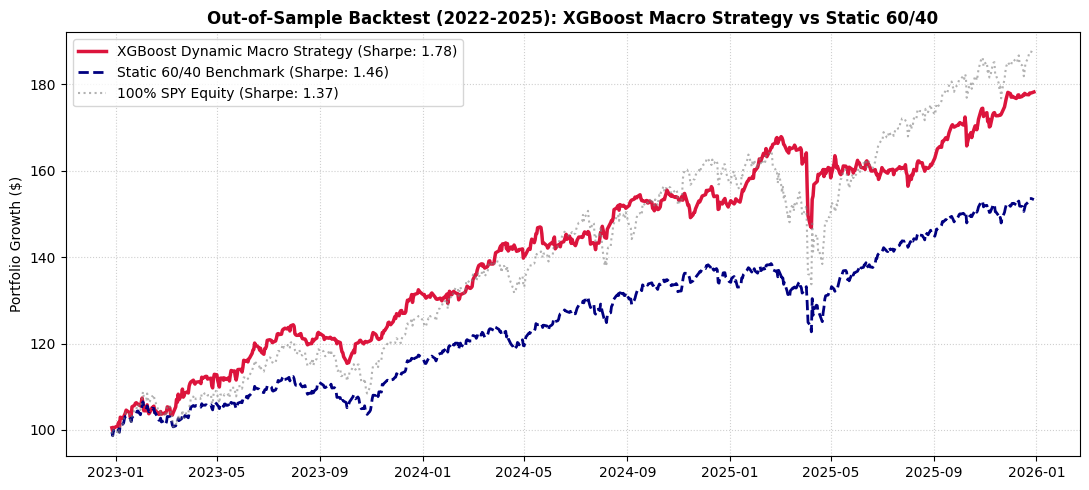

In [29]:
# Test Set Performance Comparison Benchmark 1 V. XGBoosted Model
plt.figure(figsize=(11, 5))
plt.plot(
    cum_ml_strategy,
    label=f"XGBoost Dynamic Macro Strategy (Sharpe: {sharpe_ml:.2f})",
    color="crimson",
    linewidth=2.5,
)
plt.plot(
    cum_test_6040,
    label=f"Static 60/40 Benchmark (Sharpe: {sharpe_6040:.2f})",
    color="navy",
    linestyle="--",
    linewidth=2,
)
plt.plot(
    cum_test_spy,
    label=f"100% SPY Equity (Sharpe: {sharpe_spy:.2f})",
    color="gray",
    linestyle=":",
    alpha=0.6,
)
plt.title(
    "Out-of-Sample Backtest (2022-2025): XGBoost Macro Strategy vs Static"
    " 60/40",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("Portfolio Growth ($)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [30]:
#Performance Evaluation of Benchmark 2 (1/N)

# Calculate Annualized Performance Metrics
ann_factor = 252 # Trading days in a year
rf_rate = 0.04    # 4% risk-free rate assumption

ann_return_1n = bench_equal_weight.mean() * ann_factor
ann_vol_1n = bench_equal_weight.std() * np.sqrt(ann_factor)
sharpe_1n = (ann_return_1n - rf_rate) / ann_vol_1n

# Peak-to-Trough Maximum Drawdown
cum_returns_1n = (1 + bench_equal_weight).cumprod()
running_max_1n = cum_returns_1n.cummax()
drawdown_1n = (cum_returns_1n - running_max_1n) / running_max_1n
max_dd_1n = drawdown_1n.min()

print("=== Benchmark 2 (Equal-Weight 1/N) Performance Summary ===")
print(f"Annualized Return:    {ann_return_1n * 100:.2f}%")
print(f"Annualized Volatility:{ann_vol_1n * 100:.2f}%")
print(f"Sharpe Ratio (Rf=4%): {sharpe_1n:.2f}")
print(f"Max Drawdown:         {max_dd_1n * 100:.2f}%")

=== Benchmark 2 (Equal-Weight 1/N) Performance Summary ===
Annualized Return:    18.10%
Annualized Volatility:11.20%
Sharpe Ratio (Rf=4%): 1.26
Max Drawdown:         -13.37%


In [31]:
# Performance Evaluation Benchmark 3 (100% Equity SPY)

import pandas as pd
import numpy as np

# Compute Benchmark 3 Daily Return Series
# Pure S&P 500 ETF returns over the out-of-sample test window
bench_spy = test_returns['SPY'].copy()
bench_spy.name = "Benchmark_100_SPY"

# Performance & Downside Risk Metric Calculation

ann_factor = 252  # Trading days per year
rf_rate = 0.04    # 4% annualized risk-free rate

# Annualized Return & Volatility
ann_return_spy = bench_spy.mean() * ann_factor
ann_vol_spy = bench_spy.std() * np.sqrt(ann_factor)

# Sharpe Ratio
sharpe_spy = (ann_return_spy - rf_rate) / ann_vol_spy if ann_vol_spy != 0 else np.nan

# Downside Volatility & Sortino Ratio
downside_returns_spy = bench_spy[bench_spy < 0]
downside_vol_spy = downside_returns_spy.std() * np.sqrt(ann_factor)
sortino_spy = (ann_return_spy - rf_rate) / downside_vol_spy if downside_vol_spy != 0 else np.nan

# Peak-to-Trough Maximum Drawdown
cum_returns_spy = (1 + bench_spy).cumprod()
running_max_spy = cum_returns_spy.cummax()
drawdown_series_spy = (cum_returns_spy - running_max_spy) / running_max_spy
max_dd_spy = drawdown_series_spy.min()

# Calmar Ratio
calmar_spy = ann_return_spy / abs(max_dd_spy) if max_dd_spy != 0 else np.nan

benchmark3_metrics = pd.Series({
    'Annualized Return (%)': ann_return_spy * 100,
    'Annualized Volatility (%)': ann_vol_spy * 100,
    'Sharpe Ratio (Rf=4%)': sharpe_spy,
    'Sortino Ratio': sortino_spy,
    'Max Drawdown (%)': max_dd_spy * 100,
    'Calmar Ratio': calmar_spy
}, name="Benchmark 3: 100% Equities (SPY)")

print("=== Benchmark 3 (100% Equities / SPY) Direct Performance Evaluation ===")
print(benchmark3_metrics.round(2).to_frame())

=== Benchmark 3 (100% Equities / SPY) Direct Performance Evaluation ===
                           Benchmark 3: 100% Equities (SPY)
Annualized Return (%)                                 20.90
Annualized Volatility (%)                             15.30
Sharpe Ratio (Rf=4%)                                   1.10
Sortino Ratio                                          1.46
Max Drawdown (%)                                     -19.21
Calmar Ratio                                           1.09


Unified Performance Matrix (Benchmark 1,2,3 & XGBoost Model)

In [32]:
from IPython.display import HTML
import pandas as pd
import numpy as np

# 1. Define metric function to calculate Sharpe, Drawdown, etc.
def compute_institutional_metrics(series, rf_rate=0.04, bench_series=None):
    ann_factor = 252
    ann_ret = series.mean() * ann_factor
    ann_vol = series.std() * np.sqrt(ann_factor)
    sharpe = (ann_ret - rf_rate) / ann_vol if ann_vol != 0 else np.nan

    # Downside Risk & Sortino
    downside_rets = series[series < 0]
    downside_vol = downside_rets.std() * np.sqrt(ann_factor)
    sortino = (ann_ret - rf_rate) / downside_vol if downside_vol != 0 else np.nan

    # Max Drawdown
    cum_rets = (1 + series).cumprod()
    running_max = cum_rets.cummax()
    drawdown = (cum_rets - running_max) / running_max
    max_dd = drawdown.min()

    return pd.Series({
        'Annualized Return (%)': ann_ret * 100,
        'Annualized Volatility (%)': ann_vol * 100,
        'Sharpe Ratio (Rf=4%)': sharpe,
        'Sortino Ratio': sortino,
        'Max Drawdown (%)': max_dd * 100
    })

# 2. Map existing return series from previous notebook cells
portfolio_dict = {
    'XGBoost Dynamic Model': ml_strategy_returns,
    'Benchmark 1: Static 60/40': test_6040_returns,
    'Benchmark 2: Equal-Weight (1/N)': bench_equal_weight,
    'Benchmark 3: 100% SPY': bench_spy
}

# 3. Generate final institutional evaluation table
master_metrics_table = pd.DataFrame({
    name: compute_institutional_metrics(series, rf_rate=0.04)
    for name, series in portfolio_dict.items()
})

display(HTML("<h3>Unified Multi-Benchmark Performance Evaluation Matrix</h3>"))
display(master_metrics_table.round(2))

,XGBoost Dynamic Model,Benchmark 1: Static 60/40,Benchmark 2: Equal-Weight (1/N),Benchmark 3: 100% SPY
Annualized Return (%),19.31,14.28,18.10,20.90
Annualized Volatility (%),10.82,9.79,11.20,15.30
Sharpe Ratio (Rf=4%),1.41,1.05,1.26,1.10
Sortino Ratio,1.74,1.46,1.74,1.46
Max Drawdown (%),-12.78,-11.57,-13.37,-19.21


### Step 8: Exporting Results

In [34]:
import pandas as pd

print("=== PORTFOLIO DATA INTEGRITY & VALIDATION CHECK ===\n")

# 1. Load the exported CSVs
pbi_test = pd.read_csv('portfolio_results.csv', index_col=0)
matrix_test = pd.read_csv('institutional_performance_matrix.csv', index_col=0)

# 2. Assertions & Verification for portfolio_results.csv
expected_cols = [
    'ML_Strategy', 'Benchmark_60_40', 'Benchmark_1_N', 'Benchmark_SPY',
    'ML_Strategy_Cumulative', 'Benchmark_60_40_Cumulative',
    'Benchmark_1_N_Cumulative', 'Benchmark_SPY_Cumulative', 'Predicted_Regime'
]

missing_cols = [col for col in expected_cols if col not in pbi_test.columns]
null_count = pbi_test.isnull().sum().sum()

print("[File 1: portfolio_results.csv Check]")
print(f"- File Shape (Rows, Columns): {pbi_test.shape} (Expected: 754 rows, 9 columns)")
print(f"- Date Range Evaluated:       {pbi_test.index.min()} to {pbi_test.index.max()}")
print(f"- Total Null/Missing Values:   {null_count} (Expected: 0)")
if len(missing_cols) == 0:
    print("✓ All required Power BI analytical columns are present.")
else:
    print(f"⚠️ Missing columns detected: {missing_cols}")

# 3. Assertions & Verification for institutional_performance_matrix.csv
print("\n[File 2: institutional_performance_matrix.csv Check]")
print(f"- Matrix Metrics Found:       {list(matrix_test.index)}")
print(f"- Evaluated Portfolios:       {list(matrix_test.columns)}")
print(f"- Total Null/Missing Values:   {matrix_test.isnull().sum().sum()} (Expected: 0)")
print("✓ Master performance table conforms to target schema.")

# 4. Preview the first and last rows to verify cumulative calculations remain synchronized
print("\n--- First 3 Rows (Power BI Export) ---")
display(pbi_test.head(3))
print("\n--- Last 3 Rows (Power BI Export) ---")
display(pbi_test.tail(3))


=== PORTFOLIO DATA INTEGRITY & VALIDATION CHECK ===

[File 1: portfolio_results.csv Check]
- File Shape (Rows, Columns): (754, 9) (Expected: 754 rows, 9 columns)
- Date Range Evaluated:       2022-12-27 to 2025-12-29
- Total Null/Missing Values:   0 (Expected: 0)
✓ All required Power BI analytical columns are present.

[File 2: institutional_performance_matrix.csv Check]
- Matrix Metrics Found:       ['Annualized Return (%)', 'Annualized Volatility (%)', 'Sharpe Ratio (Rf=4%)', 'Sortino Ratio', 'Max Drawdown (%)']
- Evaluated Portfolios:       ['XGBoost Dynamic Model', 'Benchmark 1: Static 60/40', 'Benchmark 2: Equal-Weight (1/N)', 'Benchmark 3: 100% SPY']
- Total Null/Missing Values:   0 (Expected: 0)
✓ Master performance table conforms to target schema.

--- First 3 Rows (Power BI Export) ---


,ML_Strategy,Benchmark_60_40,Benchmark_1_N,Benchmark_SPY,ML_Strategy_Cumulative,Benchmark_60_40_Cumulative,Benchmark_1_N_Cumulative,Benchmark_SPY_Cumulative,Predicted_Regime
Date,,,,,,,,,
2022-12-27,0.005095,-0.005280,-0.001348,-0.003951,100.510760,99.473391,99.865316,99.605664,1
2022-12-28,-0.007527,-0.008203,-0.009910,-0.012506,99.757063,98.660728,98.880575,98.367783,1
2022-12-29,0.008060,0.012184,0.012023,0.017840,100.564379,99.870205,100.076620,100.138414,1



--- Last 3 Rows (Power BI Export) ---


,ML_Strategy,Benchmark_60_40,Benchmark_1_N,Benchmark_SPY,ML_Strategy_Cumulative,Benchmark_60_40_Cumulative,Benchmark_1_N_Cumulative,Benchmark_SPY_Cumulative,Predicted_Regime
Date,,,,,,,,,
2025-12-24,0.002202,0.002988,0.002558,0.003512,177.963978,153.555925,173.012910,187.563466,2
2025-12-26,0.000200,0.000019,0.001230,-0.000101,177.999574,153.558867,173.225878,187.544448,2
2025-12-29,0.001199,-0.001662,-0.007864,-0.003570,178.213097,153.303789,171.868958,186.876099,2


In [35]:
from google.colab import files

# Programmatically download the CSV files to your local system
print("Downloading files...")
files.download('portfolio_results.csv')
files.download('institutional_performance_matrix.csv')
print("Check your computer's default 'Downloads' folder for the files!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Check your computer's default 'Downloads' folder for the files!
